In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline



In [4]:
#read csv
df= pd.read_csv('/Users/sergio/Desktop/IRONHACK/Weeks 5 to 9/Week 05/lab01/amz_uk_price_prediction_dataset.csv')

In [5]:
#drop uid column
df.head()
df.drop("uid", inplace=True, axis=1)


In [61]:
df['category'].value_counts().sort_values(ascending=False).head(10)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

In [44]:
#generate crosstab
crosstab_result=pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [42]:
#lest´s show the proportion

crosstab_results_pct=crosstab_result
crosstab_results_pct

isBestSeller,False,True,proportion_bestSeller%
category,,,
3D Printers,247,1,0.403226
3D Printing & Scanning,4065,2,0.049176
Abrasive & Finishing Products,245,5,2.000000
Action Cameras,1696,1,0.058928
Adapters,251,3,1.181102
...,...,...,...
Wind Instruments,243,7,2.800000
Window Treatments,234,5,2.092050
Women,17559,213,1.198515


In [43]:
crosstab_result_pct

isBestSeller,False,True
category,,
3D Printers,0.0,0.0
3D Printing & Scanning,0.0,0.0
Abrasive & Finishing Products,0.0,0.0
Action Cameras,0.0,0.0
Adapters,0.0,0.0
...,...,...
Wind Instruments,0.0,0.0
Window Treatments,0.0,0.0
Women,0.0,0.0


In [33]:
crosstab_result

isBestSeller,False,True,proportion_bestSeller%
category,,,
3D Printers,247,1,0.403226
3D Printing & Scanning,4065,2,0.049176
Abrasive & Finishing Products,245,5,2.000000
Action Cameras,1696,1,0.058928
Adapters,251,3,1.181102
...,...,...,...
Wind Instruments,243,7,2.800000
Window Treatments,234,5,2.092050
Women,17559,213,1.198515


In [45]:
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


From the crosstab between Category and isBestSeller, we can observe the following: 

- Most categories have between 1 and 5 best sellers.
- Women category has 213 best sellers, while having 17559. We can conclude that it´s one 
- Something interesting is that Wind Instruments category has the highest ratio of best sellers per product with a percentage of 2.8% 

In [46]:
#Now let´s try performing chi square test for these variables
from scipy.stats import chi2_contingency
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

- H0 -> Both variables are independent; P value>=0.05 
- H1-> Variables have a significant association betweenthem; P value <= 0.05

- In this case the p value is extremelt low, rounded to 0, meaning that the variables might be significantly related. 

- The null hypothesis is rejected, category and besteller status are not independent.

In [47]:
#Now let´s compute Cramer's V to test the strenght of associatio between best -seller status and category. 
from scipy.stats.contingency import association 

association(crosstab_result, method='cramer')


0.1222829439760564

- Cramer's V measure suggest a weak association between the variables, although they are statistically significant, the strenght is not strong according to Cramers measure. 

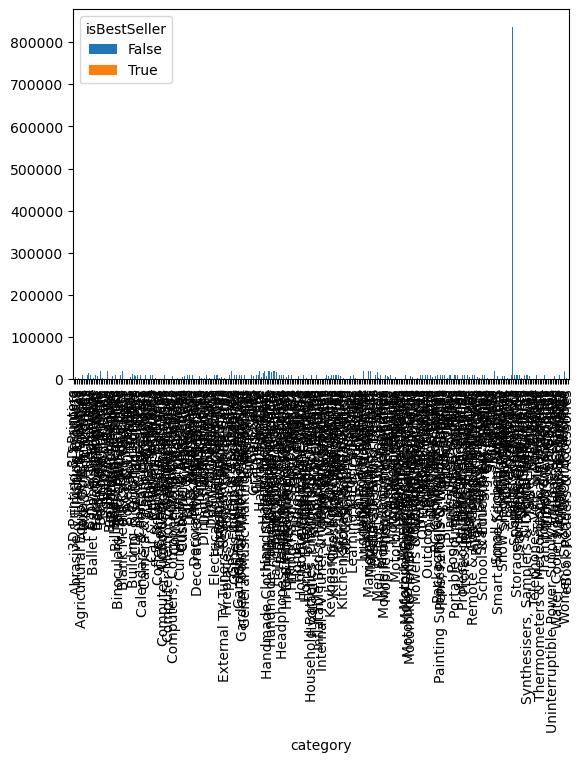

In [48]:
#let´s visualize the relationship using a stacked bar chart 
crosstab_result.plot(kind="bar", stacked=True)
plt.show()

In [62]:
#visualization of all categories is veryt difficult because there are more than 296 categories
df['category'].nunique()



296

PART 2 - Exploring product prices and ratings across categories and brands
- Investigate how different product categories influence product prices

In [64]:
#1. Remove outliers in product prices using IQR 
#let´s program tukeys  test: 

def tukeys_test_outliers(data):
    Q1=data.quantile(0.25)
    Q3= data.quantile(0.75)
    IQR= Q3-Q1

    lower_bound= Q1 - 1.5*IQR
    upper_bound=Q3 + 1.5*IQR

    outliers=data[(data<lower_bound) | (data > upper_bound)]

    return outliers 

In [66]:
outliers=tukeys_test_outliers(df['price'])
outliers

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64

In [67]:
df_no_outliers = df[~df['price'].isin(outliers)]

In [68]:
df_no_outliers

,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


/var/folders/sh/7twmcx310r92k4q4qz3tvs2m0000gn/T/ipykernel_7268/2482098719.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_no_outliers_top20, x='category', y='price', palette="coolwarm")


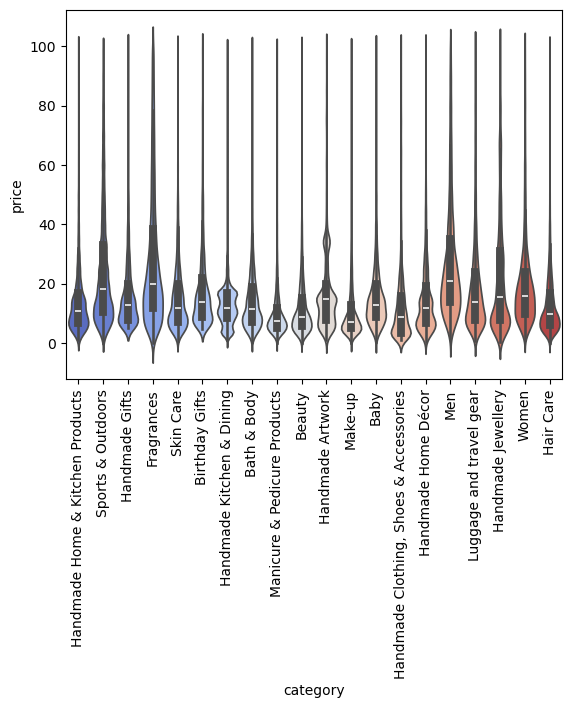

In [77]:
#violin plot: 
top20_cat=df_no_outliers['category'].value_counts().sort_values(ascending=False).head(20)
df_no_outliers_top20=df_no_outliers[df_no_outliers['category'].isin(top20_cat.index)]
sns.violinplot(data=df_no_outliers_top20, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=90) 
plt.show()

- We can see that the cop 20 categories, share a similar price structure, centered around 0 and 20. We can conclude that the categories with the most listings share a similar price structure. There are a few categories (Fragrances, Handmade Artwork, Men, and Women), that show wider proice distributions and longer tails, having more products in an upper range between 20 and 40 than the others. 

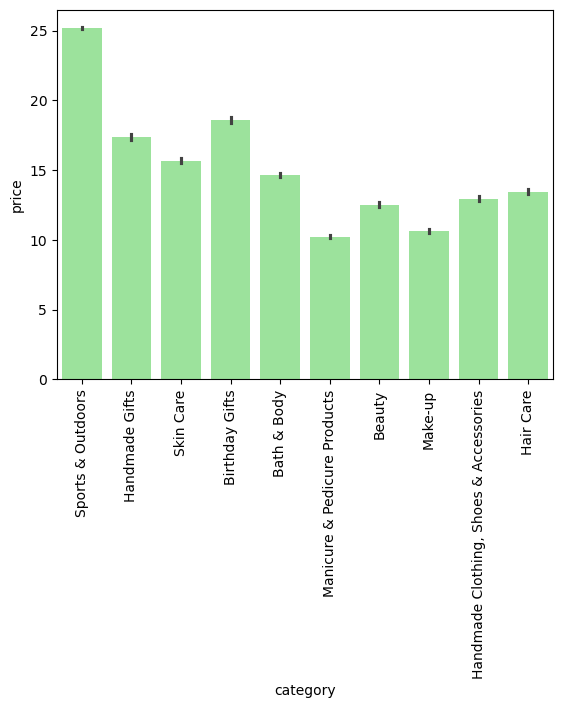

In [79]:
#bar chart to compare average price of products for the top 10 product categories based on count
#lets filter our the top 10 product categories by count
top10_cat=df_no_outliers['category'].value_counts().sort_values(ascending=False).head(10)
df_no_outliers_top10=df_no_outliers[df_no_outliers['category'].isin(top10_cat.index)]

#plot the bar chart (cat vs continuous)
sns.barplot(data=df_no_outliers_top10, x='category', y='price', color='lightgreen')
plt.xticks(rotation=90) 
plt.show()

- Sports & Outdoor has the highest average price with an average of 25 

/var/folders/sh/7twmcx310r92k4q4qz3tvs2m0000gn/T/ipykernel_7268/2218740370.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_no_outliers_top10, x='category', y='stars', palette="coolwarm")


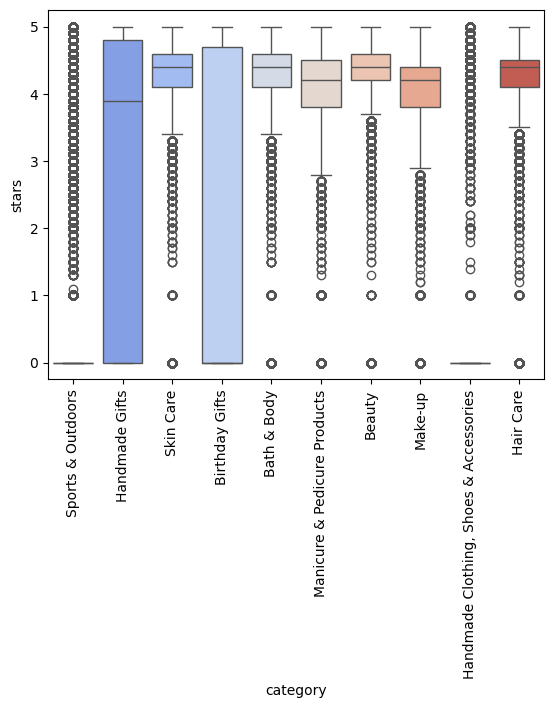

In [86]:
#now lets plot box plot:

sns.boxplot(data=df_no_outliers_top10, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=90)
plt.show()

- the highest median rating category seems to be Hair Care

PART 3:  Investigating the interplay bewteen product prices and ratings 

- Analyze how product ratings correlate with product prices - continuous vs continuous variable

In [91]:
#Check Pearson Corr. coeficient: 

pearson_correlation= df['price'].corr(df['stars'])
spearman_correlation= df['price'].corr(df['stars'], method='spearman')


pearson_correlation, spearman_correlation

(np.float64(-0.1249067326214869), np.float64(-0.13316425462433937))

- according to the correlations, the relationship between price and ratings is very weak, meaning prices do not relate with product ratings, they seem to be independent from each other 

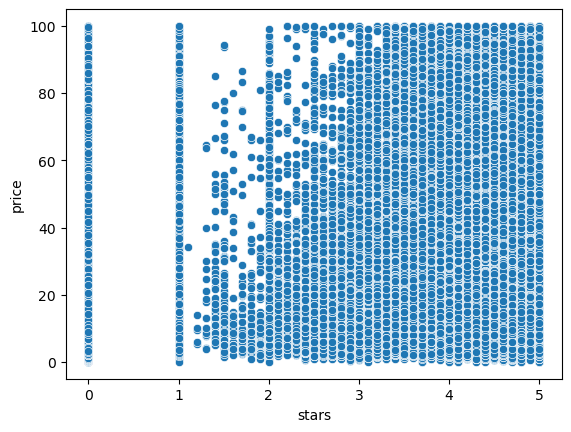

In [93]:
#lets do a scatter plot

sns.scatterplot(data=df_no_outliers_top20, x='stars', y='price')
plt.show()

In [94]:
#we can not observe any pattern, the prices are scattered all over different product ratings. Basically we could find any kind of product with any kind of price with any kind of rating, there is no tendency or pattern. That makes sense as we found an almost non existent correlatino between those two variables

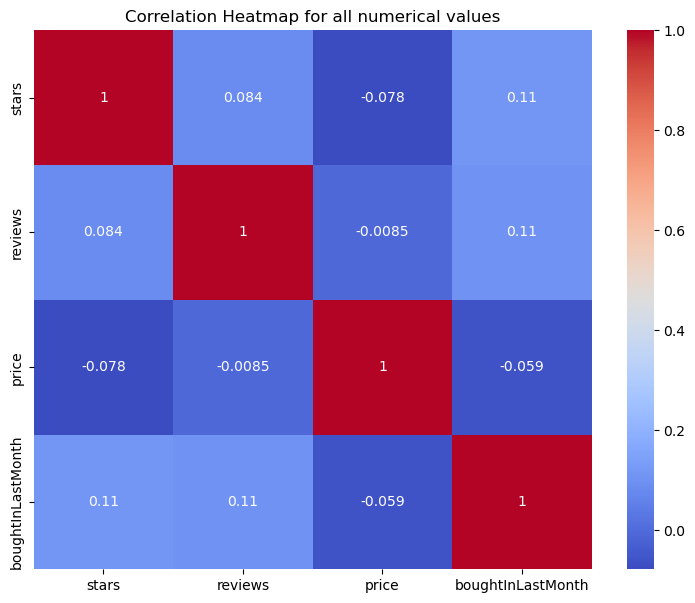

In [97]:
#lets try a correlation heatmap: 

# Adjusting the numerical dataframe by removing the moved columns
df_numerical = df_no_outliers.select_dtypes("number")
correlation_matrix=df_numerical.corr()

#set matpotlib figure 
plt.figure(figsize=(9, 7))

#draw the heatmap

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title('Correlation Heatmap for all numerical values')
plt.show()

In [ ]:
#we can see there is no clear correlation between any of the numerical variables 

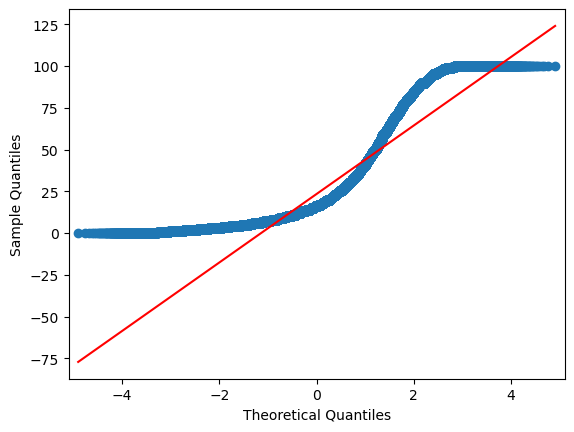

In [102]:
#let´s do qq plot for prices
import statsmodels.api as sm

sm.qqplot(df_no_outliers['price'], line='s');
plt.show()

In [ ]:
#Even after removing the outliers, we can see in the qq plot that prices are not normally distributed, with a clear right sided skew, meaning most prices are in the lower range with few outliers with high prices. 